In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import sys
sys.path.append("../../tools")
import functions as func


In [50]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'axes.linewidth': 0.5,
    'legend.fontsize': 7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5,
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

def compare_common_rows(folder_path, folder_names, emer_property, tol=1e-8):
    """
    Find identical rows across all folders for each richness.

    Parameters
    ----------
    folder_path : str
        Parent directory containing the four folders.
    folder_names : list
        Folder names.
    emer_property : str
        Column name of the emergent property.
    tol : float
        Numerical tolerance for matching rows.

    Returns
    -------
    result_df : DataFrame
        Each row represents one common sample across four folders.
    """

    # Extract re values from folder names
    re_values = [
        int(re.search(r"re(\d+)", name).group(1))
        for name in folder_names
    ]

    # Sort folders according to re
    order = np.argsort(re_values)
    folder_names = [folder_names[i] for i in order]
    re_values = [re_values[i] for i in order]

    results = []

    # Get all files in each folder, indexed by (n_real, MaxNum)
    file_dicts = []

    for folder in folder_names:

        files = glob.glob(os.path.join(folder_path, folder, "*.csv"))

        file_dict = {}

        for file in files:
            n_real, MaxNum = func.get_species_info(file)
            file_dict[(n_real, MaxNum)] = file

        file_dicts.append(file_dict)


    # Find common (n_real, MaxNum) across all folders
    common_richness = set(file_dicts[0].keys())

    for d in file_dicts[1:]:
        common_richness &= set(d.keys())

    results = []

    for n_real, MaxNum in sorted(common_richness):

        feature_cols = MaxNum**2 + MaxNum

        # Read corresponding richness files from all folders
        dfs = [
            pd.read_csv(d[(n_real, MaxNum)])
            for d in file_dicts
        ]

        # Extract feature matrices and emergent properties
        X_list = [
            df.iloc[:, :feature_cols].to_numpy(dtype=float)
            for df in dfs
        ]

        Y_list = [
            df[emer_property].to_numpy(dtype=float)
            for df in dfs
        ]

        # Check feature dimensions
        if any(X.shape[1] != feature_cols for X in X_list):
            raise ValueError(f"Feature dimension mismatch: {filename}")

        # Match rows across all folders using tolerance
        # Quantization is used to make approximate matching efficient
        keys_list = [
            np.round(X / tol).astype(np.int64)
            for X in X_list
        ]

        # Convert rows to tuples for matching
        dict_list = []

        for keys, y in zip(keys_list, Y_list):

            row_dict = {}

            for key, value in zip(keys, y):
                key = tuple(key)

                # Keep the first occurrence if duplicated
                if key not in row_dict:
                    row_dict[key] = value

            dict_list.append(row_dict)

        # Find common keys across all four folders
        common_keys = set(dict_list[0].keys())

        for d in dict_list[1:]:
            common_keys &= set(d.keys())

        print(f"Richness {n_real}: {len(common_keys)} common rows")

        # Extract corresponding emergent properties
        for key in common_keys:

            values = [d[key] for d in dict_list]

            results.append({
                "richness": n_real,
                "sample": key,
                **{
                    f"re{re_value}": value
                    for re_value, value in zip(re_values, values)
                }
            })

    result_df = pd.DataFrame(results)

    return result_df

def plot_common_rows(result_df, n_lines=100, richness=None, random_state=42, save_path=None):

    # Select specific richness
    if richness is not None:
        result_df = result_df[result_df["richness"] == richness]

    if len(result_df) == 0:
        print(f"No data found for richness={richness}")
        return

    re_cols = [
        col for col in result_df.columns
        if col.startswith("re")
    ]

    re_values = [int(col[2:]) for col in re_cols]

    order = np.argsort(re_values)
    re_cols = [re_cols[i] for i in order]
    re_values = [re_values[i] for i in order]

    # Randomly sample n_lines rows
    if len(result_df) > n_lines:
        plot_df = result_df.sample(n=n_lines, random_state=random_state)
    else:
        plot_df = result_df.copy()

    fig, ax = plt.subplots(figsize=(2, 2))

    colors = ['#F15F6C', '#32BDA8', '#BFE5E8', '#E8D0AE',
            '#567589', '#7297A0', '#3E516F', '#76888C',
            '#D61F3E', '#EEB21C', '#8CA06B']

    for i, (_, row) in enumerate(plot_df.iterrows()):

        y = row[re_cols].to_numpy(dtype=float)

        ax.plot(
            re_values, y,
            color=colors[i % len(colors)],
            #color="grey",
            alpha=0.6,
            linewidth=0.8
        )

    ax.tick_params(direction='in')
    ax.set_xlabel("Number of initializations", fontsize=12)
    #ax.set_ylabel("Species-level transition", fontsize=12)
    #ax.set_ylabel(r"$\mathcal{H}$", fontsize=12)
    ax.set_ylabel(r"$\mathcal{D}$", fontsize=12)
    ax.set_xticks(re_values)

    ax.tick_params(labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches="tight", transparent=True)

    plt.show()

def plot_violin_common_rows(result_df, richness=None, save_path=None):

    # Select specific richness
    if richness is not None:
        result_df = result_df[result_df["richness"] == richness]

    if len(result_df) == 0:
        print(f"No data found for richness={richness}")
        return

    re_cols = [
        col for col in result_df.columns
        if col.startswith("re")
    ]

    re_values = [int(col[2:]) for col in re_cols]

    order = np.argsort(re_values)
    re_cols = [re_cols[i] for i in order]
    re_values = [re_values[i] for i in order]

    data = [
        result_df[col].dropna().to_numpy()
        for col in re_cols
    ]

    fig, ax = plt.subplots(figsize=(4, 2))

    parts = ax.violinplot(
        data,
        positions=re_values,
        widths=25,
        showmeans=False,
        showmedians=True,
        showextrema=False
    )

    # Set violin style
    for pc in parts["bodies"]:
        pc.set_facecolor("#71b4c3")
        pc.set_edgecolor("none")
        pc.set_alpha(0.65)

    parts["cmedians"].set_color("black")
    parts["cmedians"].set_linewidth(1.2)

    ax.tick_params(direction='in')
    ax.set_xlabel("Number of initializations", fontsize=12)
    #ax.set_ylabel(r"$\mathcal{H}$", fontsize=12)
    #ax.set_ylabel(r"$N$", fontsize=12)
    ax.set_ylabel("Species-level transition", fontsize=12)
    #ax.set_ylim(0, 0.4)

    ax.set_xticks(re_values)
    ax.set_yticks([0,1])

    ax.tick_params(labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches='tight', transparent=True,)

    plt.show()

def plot_barchart_common_rows(result_df, richness=None, save_path=None):

    # Select specific richness
    if richness is not None:
        result_df = result_df[result_df["richness"] == richness]

    if len(result_df) == 0:
        print(f"No data found for richness={richness}")
        return

    re_cols = [
        col for col in result_df.columns
        if col.startswith("re")
    ]

    re_values = [int(col[2:]) for col in re_cols]

    order = np.argsort(re_values)
    re_cols = [re_cols[i] for i in order]
    re_values = [re_values[i] for i in order]

    # Count the number of 0 and 1 for each RE
    count_0 = [(result_df[col] == 0).sum() for col in re_cols]
    count_1 = [(result_df[col] == 1).sum() for col in re_cols]

    fig, ax = plt.subplots(figsize=(4,2))

    width = 15

    ax.bar(
        np.array(re_values) - width / 2,
        count_0,
        width=width,
        color="#71b4c3",
        edgecolor="none",
        label="0"
    )

    ax.bar(
        np.array(re_values) + width / 2,
        count_1,
        width=width,
        color="#E8D0AE",
        edgecolor="none",
        label="1"
    )

    ax.tick_params(direction='in')
    ax.set_xlabel("Number of initializations", fontsize=12)
    #ax.set_ylabel("Species-level transition", fontsize=12)
    ax.set_ylabel("Persistent fluctuation", fontsize=12)

    ax.set_xticks(re_values)

    ax.tick_params(labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches='tight', transparent=True)

    plt.show()
    

In [ ]:
folder_path = r"../../Databases/Ver1.9"

folder_names = [
    "ver1.9.6_re25ti800",
    "ver1.9.6_re50ti800",
    "ver1.9.6_re75ti800",
    "ver1.9.6_re100ti800",
    "ver1.9.6_re150ti800",
    "ver1.9.6_re200ti800",
    "ver1.9.6_re250ti800",
    "ver1.9.6_re300ti800"
]

result_df = compare_common_rows(
    folder_path=folder_path,
    folder_names=folder_names,
    #emer_property="states_number",
    #emer_property="relative_H",
    #emer_property="relative_D",
    #emer_property="switching_sp1",
    emer_property="fluctuation",
    tol=1e-8
)


Richness 3: 1266 common rows
Richness 4: 1252 common rows
Richness 5: 1243 common rows
Richness 6: 1236 common rows
Richness 7: 1232 common rows
Richness 8: 1221 common rows
Richness 9: 1215 common rows
Richness 10: 1222 common rows
Richness 11: 1220 common rows
Richness 12: 1203 common rows
Richness 13: 1190 common rows
Richness 14: 1205 common rows
Richness 15: 1183 common rows
Richness 16: 1177 common rows
Richness 17: 1187 common rows
Richness 18: 1170 common rows
Richness 19: 1173 common rows
Richness 20: 1164 common rows


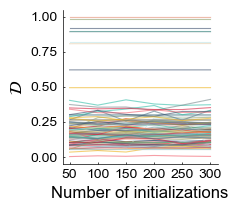

In [33]:
plot_common_rows(
    result_df,
    n_lines=100,
    richness=20,
    random_state=42,
    save_path="common_rows_comparison.pdf"
)

# 保存提取的数据
result_df.to_csv("common_rows_comparison.csv", index=False)


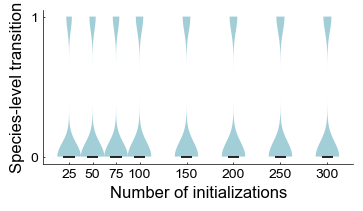

In [36]:
plot_violin_common_rows(result_df, 
                        richness=20, 
                        save_path="common_rows_violin.pdf")


In [53]:
result_df.iloc[:, 2:10] = (result_df.iloc[:, 2:10] != 0).astype(int)


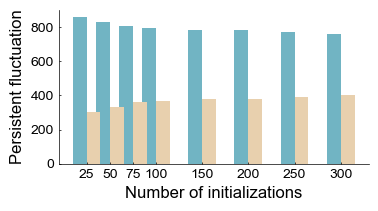

In [54]:
plot_barchart_common_rows(result_df, 
                        richness=20, 
                        save_path="common_rows_barchart.pdf")
